# 06 · Calibration, decisions, uncertainty and the test

**Question:** can the chosen model's probabilities be read at face value, how should
they be turned into decisions, how stable is it over time, and how does it do on months
no choice was ever based on?

Everything up to section 6 uses validation months only. Section 7 scores the test months
(October 2022 – March 2023) once, with every choice already fixed.

In [1]:
import json

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.calibration import calibration_curve
from sklearn.metrics import average_precision_score, log_loss

from accidents import benchmark, calibrate, config, evaluate, export, features, models, plots

plots.use_style()
pd.set_option("display.width", 160)
FINAL = config.ROOT / "data" / "processed" / "final"
FINAL.mkdir(parents=True, exist_ok=True)

selection = json.loads((benchmark.OUT / "selection.json").read_text())
chosen = selection["chosen"]
spec = models.MODELS[chosen]
result = json.loads((benchmark.OUT / f"{chosen}.json").read_text())
saved = joblib.load(benchmark.OUT / f"{chosen}.joblib")
model, medians = saved["model"], saved["medians"]
print(f"chosen model: {chosen} — {selection['reason']}")

table = pd.read_parquet(config.MODEL_TABLE)
valid = table[table["split"] == "valid"].reset_index(drop=True)
test = table[table["split"] == "test"].reset_index(drop=True)
x_valid, y_valid = benchmark.prepare(spec, valid, medians)
valid_days = valid["start_time"].dt.normalize().to_numpy()

chosen model: lightgbm — LightGBM is the best exportable model; TabM's lead (0.0012 AP, 95% interval [-0.0010, 0.0036]) is within noise


## 0 · Final fit: should the last two training months join the model?

The benchmark held out February–March 2022 to decide when boosting stops, so the chosen
model never learned from the months closest to validation. A boosting model can be refitted
on all training months for the number of rounds early stopping chose. Both versions are
compared on validation months; the refit is kept only if it is at least as good.

In [2]:
p_benchmark = model.predict_proba(x_valid)[:, 1]
final_fit = "benchmark model"
if chosen in ("lightgbm", "xgboost", "catboost"):
    splits = benchmark.load_splits()
    all_train = pd.concat([splits["fit"], splits["stop"]])
    x_all, y_all = benchmark.prepare(spec, all_train, medians)
    refit = models.refit_all_rounds(model, x_all, y_all)
    p_refit = refit.predict_proba(x_valid)[:, 1]
    paired = evaluate.bootstrap(
        y_valid, {"benchmark": p_benchmark, "refit": p_refit}, valid_days, n_boot=500
    )
    gap_low, gap_high = evaluate.interval(paired["refit"] - paired["benchmark"])
    ap_benchmark = average_precision_score(y_valid, p_benchmark)
    ap_refit = average_precision_score(y_valid, p_refit)
    print(
        f"{models.boosting_rounds(model)} rounds; validation AP: benchmark {ap_benchmark:.4f}, "
        f"refit on all training months {ap_refit:.4f} (difference 95% interval "
        f"[{gap_low:.4f}, {gap_high:.4f}])"
    )
    if ap_refit >= ap_benchmark:
        model, final_fit = refit, "refit on all training months"
        del splits, all_train, x_all
print("final fit:", final_fit)
joblib.dump({"model": model, "medians": medians}, FINAL / "model.joblib")
p_valid_raw = model.predict_proba(x_valid)[:, 1]

684 rounds; validation AP: benchmark 0.1864, refit on all training months 0.1905 (difference 95% interval [0.0018, 0.0063])
final fit: refit on all training months


## 1 · Calibration: which mapping makes probabilities honest?

Three options: the raw scores, Platt scaling (two numbers) and isotonic regression (a
monotone table). Each calibrator is judged out of sample with 5-fold cross-fitting over
whole validation days: fitted on four folds of days, scored on the fifth.

**Rule:** keep the simplest mapping (raw, then Platt, then isotonic) that no other mapping
beats on log loss beyond noise, judged by the paired day-block bootstrap used everywhere
else in this project. A first draft treated differences under 0.00001 as ties; it was
replaced by this noise test before any test month was scored, after a dry run showed
isotonic ahead by 0.00008 with an interval spanning zero (decision record D17). Isotonic
steps would also freeze the dashboard's risk figure within each of its ~100 flat blocks.

,average_precision,roc_auc,log_loss,brier,ece
raw,0.19053,0.85884,0.10090,0.02490,0.00413
platt,0.19045,0.85880,0.10051,0.02486,0.00203
isotonic,0.18836,0.85810,0.10043,0.02483,0.00020


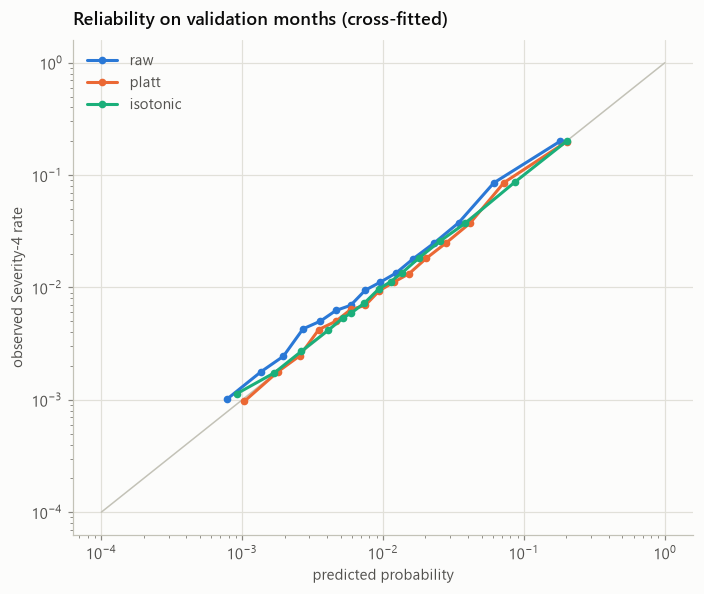

In [3]:
day_ids = pd.factorize(valid_days)[0]
fold = day_ids % 5
cross_fitted = {
    "raw": p_valid_raw.copy(),
    "platt": np.empty_like(p_valid_raw),
    "isotonic": np.empty_like(p_valid_raw),
}
for k in range(5):
    fit_rows, score_rows = fold != k, fold == k
    for name, fit in (("platt", calibrate.fit_platt), ("isotonic", calibrate.fit_isotonic)):
        calibrator = fit(p_valid_raw[fit_rows], y_valid[fit_rows])
        cross_fitted[name][score_rows] = calibrate.apply(calibrator, p_valid_raw[score_rows])
calibration_scores = pd.DataFrame(
    {name: evaluate.scores(y_valid, p) for name, p in cross_fitted.items()}
).T
display(calibration_scores.round(5))

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.plot([1e-4, 1], [1e-4, 1], color=plots.BASELINE, linewidth=1)
for i, (name, p) in enumerate(cross_fitted.items()):
    observed, predicted = calibration_curve(y_valid, p, n_bins=15, strategy="quantile")
    ax.plot(predicted, observed, "o-", color=plots.SERIES[i], markersize=4, label=name)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("predicted probability")
ax.set_ylabel("observed Severity-4 rate")
ax.set_title("Reliability on validation months (cross-fitted)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

In [4]:
loss_samples = evaluate.bootstrap(y_valid, cross_fitted, valid_days, metric=log_loss, n_boot=500)
best_name = "isotonic"
for name in ("raw", "platt"):  # simplest first
    beaten = False
    for other in cross_fitted:
        low, high = evaluate.interval(loss_samples[other] - loss_samples[name])
        print(f"log loss {other} - {name}: 95% interval [{low:.5f}, {high:.5f}]")
        beaten = beaten or high < 0
    if not beaten:
        best_name = name
        break
fitters = {"platt": calibrate.fit_platt, "isotonic": calibrate.fit_isotonic}
calibrator = calibrate.IDENTITY if best_name == "raw" else fitters[best_name](p_valid_raw, y_valid)
p_valid = calibrate.apply(calibrator, p_valid_raw)
(FINAL / "calibrator.json").write_text(json.dumps(calibrator))
print(f"calibration chosen: {best_name}")

log loss raw - raw: 95% interval [0.00000, 0.00000]
log loss platt - raw: 95% interval [-0.00060, -0.00018]
log loss isotonic - raw: 95% interval [-0.00082, -0.00014]
log loss raw - platt: 95% interval [0.00018, 0.00060]
log loss platt - platt: 95% interval [0.00000, 0.00000]
log loss isotonic - platt: 95% interval [-0.00025, 0.00008]


calibration chosen: platt


## 2 · From probability to decision

A dispatcher flags an accident when its calibrated probability exceeds a threshold. The
right threshold depends on how much worse a missed major-impact accident is than a false
alarm. With calibrated probabilities, decision theory gives it directly:
flag when p > 1 / (1 + cost ratio). The table checks that against the cheapest threshold
found empirically on validation months.

In [5]:
rows = []
grid = np.linspace(0.005, 0.5, 400)
for ratio in (5, 10, 20, 50):
    costs = [
        ratio * np.sum((p_valid < t) & (y_valid == 1)) + np.sum((p_valid >= t) & (y_valid == 0))
        for t in grid
    ]
    empirical = grid[int(np.argmin(costs))]
    theory = calibrate.cost_threshold(ratio)
    flagged = p_valid >= theory
    rows.append({
        "miss : false alarm": f"{ratio} : 1",
        "threshold 1/(1+r)": theory, "cheapest on validation": empirical,
        "recall": flagged[y_valid == 1].mean(), "precision": y_valid[flagged].mean(),
        "flags per 1,000 accidents": 1000 * flagged.mean(),
    })  # fmt: skip
decisions = pd.DataFrame(rows).set_index("miss : false alarm")
display(decisions.round(3))

,threshold 1/(1+r),cheapest on validation,recall,precision,"flags per 1,000 accidents"
miss : false alarm,,,,,
5 : 1,0.167,0.164,0.323,0.248,37.046
10 : 1,0.091,0.082,0.502,0.188,75.748
20 : 1,0.048,0.050,0.686,0.135,144.720
50 : 1,0.020,0.022,0.839,0.078,305.565


### Decision curve

Net benefit of acting on the model, against flagging every accident or none, across the
thresholds a dispatcher might use (Vickers & Elkin, 2006). The model is useful wherever
its curve is above both references.

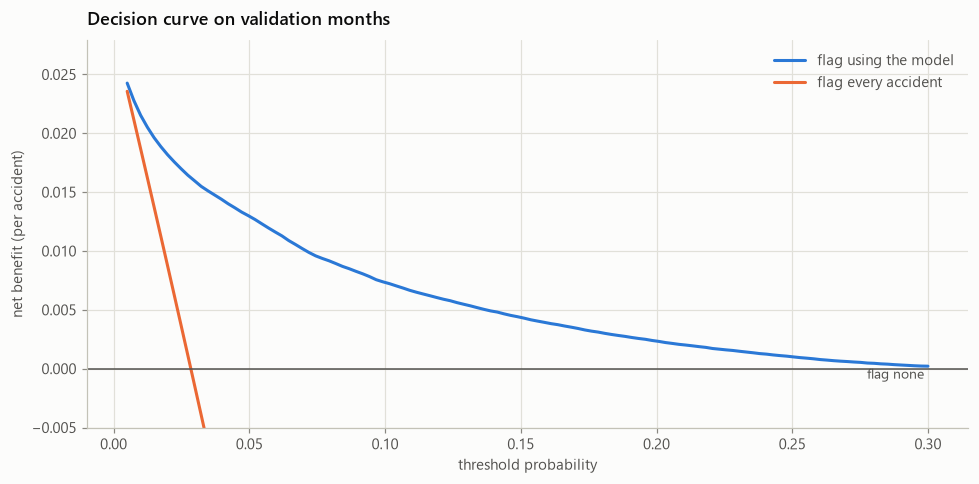

In [6]:
thresholds = np.linspace(0.005, 0.30, 120)
curve = evaluate.net_benefit(y_valid, p_valid, thresholds)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(curve["threshold"], curve["model"], color=plots.SERIES[0], label="flag using the model")
ax.plot(curve["threshold"], curve["act_on_all"], color=plots.SERIES[1], label="flag every accident")
ax.axhline(0, color=plots.INK_SECONDARY, linewidth=1)
ax.text(0.30, 0, "flag none ", ha="right", va="top", color=plots.INK_SECONDARY, fontsize=9)
ax.set_ylim(-0.005, max(curve["model"].max() * 1.15, 0.01))
ax.set_xlabel("threshold probability")
ax.set_ylabel("net benefit (per accident)")
ax.set_title("Decision curve on validation months")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

## 3 · Uncertainty: class-conditional conformal bands

Instead of a single label, each accident gets the set of outcomes the model cannot rule
out at 90% confidence per class: **minor**, **major**, **uncertain** (both) or, rarely,
**none**. The guarantee holds separately for each class when future accidents resemble
the calibration months; section 7 checks it on test.

In [7]:
conformal = evaluate.conformal_thresholds(y_valid, p_valid, alpha=0.1)
(FINAL / "conformal.json").write_text(json.dumps(conformal))
bands = evaluate.conformal_band(p_valid, conformal)
band_table = pd.crosstab(bands, y_valid, normalize="columns").rename(
    columns={0: "Severity 2", 1: "Severity 4"}
)
print(json.dumps(conformal, indent=2))
display(band_table.round(3))
print(
    "share of accidents per band:", pd.Series(bands).value_counts(normalize=True).round(3).to_dict()
)

{
  "alpha": 0.1,
  "minor_max": 0.06081447673451289,
  "major_min": 0.01188542724558661
}


col_0,Severity 2,Severity 4
row_0,,
major,0.10,0.622
minor,0.58,0.100
uncertain,0.32,0.278


share of accidents per band: {'minor': 0.566, 'uncertain': 0.319, 'major': 0.115}


## 4 · Stability over time: rolling-origin backtest

The chosen configuration is retrained three times, each time on all months up to an
origin (early stopping on that window's last two months), and scored on the next three
months. All of this happens before the test months begin.

,training rows,evaluated rows,base rate,AP,low,high
origin,,,,,,
2021-10-01,579006,353739,0.0257,0.1902,0.1784,0.2087
2022-01-01,857547,346885,0.0253,0.1718,0.1653,0.1792
2022-04-01,1219266,403664,0.0235,0.1867,0.1801,0.1920


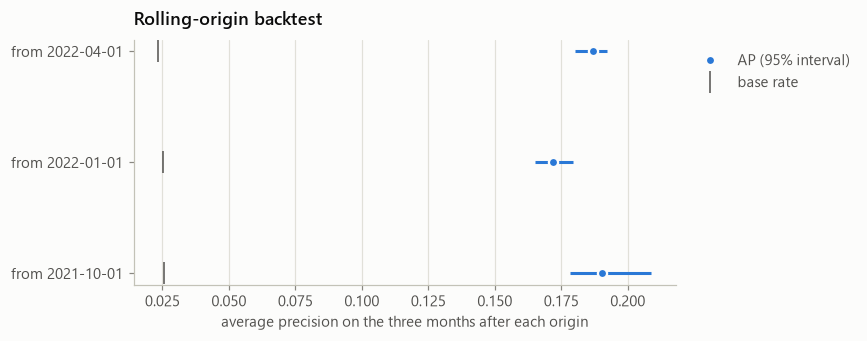

In [8]:
backtest_rows = []
for origin in ("2021-10-01", "2022-01-01", "2022-04-01"):
    origin_ts = pd.Timestamp(origin)
    stop_start = origin_ts - pd.DateOffset(months=2)
    end = origin_ts + pd.DateOffset(months=3)
    window = table[(table["start_time"] >= config.TRAIN_START) & (table["start_time"] < end)]
    fit_part = window[window["start_time"] < stop_start]
    stop_part = window[(window["start_time"] >= stop_start) & (window["start_time"] < origin_ts)]
    eval_part = window[window["start_time"] >= origin_ts]
    window_medians = models.training_medians(fit_part[features.FEATURES])
    fx, fy = benchmark.prepare(spec, fit_part, window_medians)
    sx, sy = benchmark.prepare(spec, stop_part, window_medians)
    ex, ey = benchmark.prepare(spec, eval_part, window_medians)
    fitted = spec.fit(result["best_params"], fx, fy, sx, sy)
    pe = fitted.predict_proba(ex)[:, 1]
    samples = evaluate.bootstrap(
        ey, {"m": pe}, eval_part["start_time"].dt.normalize().to_numpy(), n_boot=300
    )
    low, high = evaluate.interval(samples["m"])
    backtest_rows.append(
        {
            "origin": origin,
            "training rows": len(fx),
            "evaluated rows": len(ex),
            "base rate": ey.mean(),
            "AP": average_precision_score(ey, pe),
            "low": low,
            "high": high,
        }
    )
backtest = pd.DataFrame(backtest_rows).set_index("origin")
display(backtest.round(4))

fig, ax = plt.subplots(figsize=(8, 3.2))
yy = np.arange(len(backtest))
ax.hlines(yy, backtest["low"], backtest["high"], color=plots.SERIES[0], linewidth=2)
ax.plot(
    backtest["AP"],
    yy,
    "o",
    color=plots.SERIES[0],
    markeredgecolor=plots.SURFACE,
    markeredgewidth=1.5,
    label="AP (95% interval)",
)
ax.plot(backtest["base rate"], yy, "|", color=plots.INK_SECONDARY, markersize=14, label="base rate")
ax.set_yticks(yy, [f"from {o}" for o in backtest.index])
ax.set_xlabel("average precision on the three months after each origin")
ax.set_title("Rolling-origin backtest")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

## 5 · How much a random split would flatter the model

The same configuration trained and scored on a random split of the months before the test
(January 2021 – September 2022): 70% fit, 10% early stopping, 20% scored. Random splits put
accidents from the same days on both sides, so they measure memory of those days as well
as skill. The fair comparison is the temporal validation score of the same configuration;
the test months stay untouched until section 7.

In [9]:
before_test = (table["start_time"] >= config.TRAIN_START) & (table["split"] != "test")
period = table[before_test].sample(frac=1.0, random_state=config.SEED)
n = len(period)
fit_part, stop_part, score_part = (
    period.iloc[: int(0.7 * n)],
    period.iloc[int(0.7 * n) : int(0.8 * n)],
    period.iloc[int(0.8 * n) :],
)
random_medians = models.training_medians(fit_part[features.FEATURES])
fx, fy = benchmark.prepare(spec, fit_part, random_medians)
sx, sy = benchmark.prepare(spec, stop_part, random_medians)
rx, ry = benchmark.prepare(spec, score_part, random_medians)
random_model = spec.fit(result["best_params"], fx, fy, sx, sy)
random_ap = average_precision_score(ry, random_model.predict_proba(rx)[:, 1])
temporal_ap = average_precision_score(y_valid, p_valid_raw)
print(
    f"random-split AP: {random_ap:.4f} (base rate {ry.mean():.4f}); "
    f"temporal validation AP: {temporal_ap:.4f}"
)
del period, fit_part, stop_part, score_part, fx, sx, rx

random-split AP: 0.2507 (base rate 0.0258); temporal validation AP: 0.1905


## 6 · Frozen before the test

Model, configuration, calibration and conformal thresholds are now fixed and saved in
`data/processed/final/`. Nothing below feeds back into any of them.

In [10]:
frozen = {
    "model": chosen,
    "params": result["best_params"],
    "final_fit": final_fit,
    "calibration": best_name,
    "conformal_alpha": conformal["alpha"],
}
(FINAL / "frozen.json").write_text(json.dumps(frozen, indent=2, default=str))
print(json.dumps(frozen, indent=2, default=str))

{
  "model": "lightgbm",
  "params": {
    "learning_rate": 0.032754116729013065,
    "num_leaves": 34,
    "min_child_samples": 133,
    "subsample": 0.7135259964558893,
    "colsample_bytree": 0.9247995009590816,
    "reg_lambda": 0.07181608670660071,
    "cat_smooth": 54.908371735243506
  },
  "final_fit": "refit on all training months",
  "calibration": "platt",
  "conformal_alpha": 0.1
}


## 7 · The test months, scored once

October 2022 – March 2023: 651,635 accidents no decision was based on. Every benchmark
model is scored, with the chosen model calibrated as fixed above.

In [11]:
y_test = test["y"].to_numpy()
test_days = test["start_time"].dt.normalize().to_numpy()
test_p = {}
for name in models.MODELS:
    file = benchmark.OUT / f"{name}.joblib"
    if not file.exists():
        continue
    bundle = joblib.load(file)
    tx, _ = benchmark.prepare(models.MODELS[name], test, bundle["medians"])
    test_p[name] = bundle["model"].predict_proba(tx)[:, 1]
x_test, _ = benchmark.prepare(spec, test, medians)
test_p[f"{chosen} (final fit, calibrated)"] = calibrate.apply(
    calibrator, model.predict_proba(x_test)[:, 1]
)
test_samples = evaluate.bootstrap(y_test, test_p, test_days, n_boot=1000)
test_rows = []
for name, p in test_p.items():
    low, high = evaluate.interval(test_samples[name])
    test_rows.append({"model": name, **evaluate.scores(y_test, p), "ap_low": low, "ap_high": high})
test_scores = (
    pd.DataFrame(test_rows).set_index("model").sort_values("average_precision", ascending=False)
)
display(test_scores.round(4))

final_p = test_p[f"{chosen} (final fit, calibrated)"]
pd.DataFrame({"id": test["id"], "y": y_test, "p": final_p}).to_parquet(
    FINAL / "test_predictions.parquet", index=False
)

,average_precision,roc_auc,log_loss,brier,ece,ap_low,ap_high
model,,,,,,,
"lightgbm (final fit, calibrated)",0.1844,0.8515,0.1001,0.0244,0.0026,0.1780,0.1912
lightgbm,0.1832,0.8490,0.1004,0.0245,0.0021,0.1772,0.1897
tabm,0.1828,0.8512,0.1003,0.0245,0.0023,0.1772,0.1890
xgboost,0.1827,0.8500,0.1004,0.0245,0.0026,0.1766,0.1894
catboost,0.1819,0.8502,0.1004,0.0245,0.0024,0.1759,0.1883
realmlp,0.1787,0.8487,0.1007,0.0245,0.0012,0.1726,0.1850
logistic,0.1670,0.8358,0.1030,0.0248,0.0030,0.1613,0.1730
ebm,0.1635,0.8415,0.1031,0.0250,0.0023,0.1581,0.1690
dummy,0.0278,0.5000,0.1272,0.0270,0.0031,0.0271,0.0286


In [12]:
test_rows = []
for ratio in (5, 10, 20, 50):
    t = calibrate.cost_threshold(ratio)
    flagged = final_p >= t
    test_rows.append(
        {
            "miss : false alarm": f"{ratio} : 1",
            "threshold": t,
            "recall": flagged[y_test == 1].mean(),
            "precision": y_test[flagged].mean(),
            "flags per 1,000 accidents": 1000 * flagged.mean(),
        }
    )
display(pd.DataFrame(test_rows).set_index("miss : false alarm").round(3))

test_bands = evaluate.conformal_band(final_p, conformal)
coverage = {
    "Severity 2 covered (minor or uncertain)": np.isin(
        test_bands[y_test == 0], ["minor", "uncertain"]
    ).mean(),
    "Severity 4 covered (major or uncertain)": np.isin(
        test_bands[y_test == 1], ["major", "uncertain"]
    ).mean(),
}
print(
    "conformal coverage on test (target 0.90 each):", {k: round(v, 3) for k, v in coverage.items()}
)

,threshold,recall,precision,"flags per 1,000 accidents"
miss : false alarm,,,,
5 : 1,0.167,0.330,0.247,37.142
10 : 1,0.091,0.510,0.179,79.454
20 : 1,0.048,0.684,0.117,162.993
50 : 1,0.020,0.849,0.069,343.270


conformal coverage on test (target 0.90 each): {'Severity 2 covered (minor or uncertain)': np.float64(0.889), 'Severity 4 covered (major or uncertain)': np.float64(0.912)}


### Where the model is strong and weak (test months)

Average precision and calibration within slices. AP must be read against each slice's
own base rate: a slice with a 10% base rate makes high AP easier.

,slice,group,rows,base rate,mean predicted,AP,AP lift
37,hour band,20–23,69359,0.0399,0.0424,0.2097,5.2543
33,hour band,00–05,64421,0.0436,0.0427,0.1846,4.2326
36,hour band,16–19,166496,0.0242,0.0263,0.1831,7.5539
35,hour band,10–15,216324,0.0234,0.0257,0.1778,7.6030
34,hour band,06–09,135035,0.0255,0.0310,0.1753,6.8771
43,month,2023-03,30187,0.0312,0.0294,0.2698,8.6549
42,month,2023-02,55532,0.0344,0.0303,0.2442,7.0917
39,month,2022-11,130959,0.0282,0.0327,0.1778,6.2953
41,month,2023-01,160914,0.0262,0.0278,0.1765,6.7498
38,month,2022-10,85135,0.0267,0.0328,0.1749,6.5613


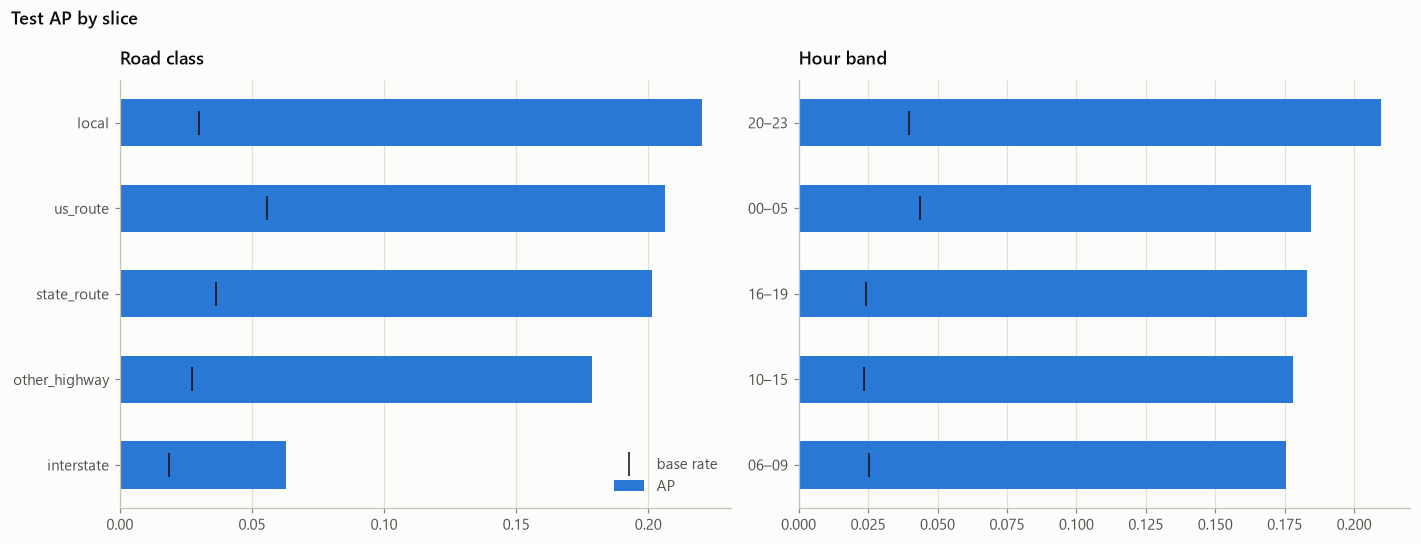

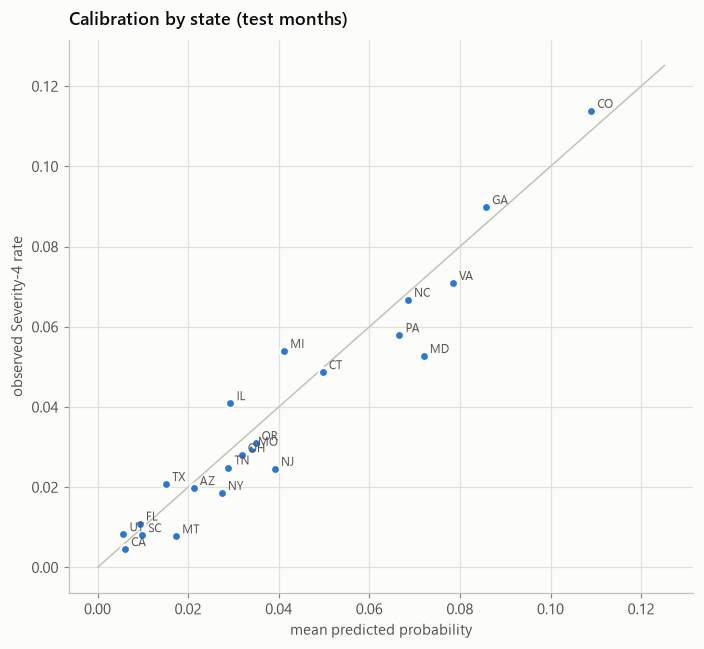

11602

In [13]:
slices = {
    "state": test["state"].astype(str),
    "road class": test["road_class"].astype(str),
    "weather": test["weather"].astype(str),
    "hour band": pd.cut(
        test["hour"], [-1, 5, 9, 15, 19, 23], labels=["00–05", "06–09", "10–15", "16–19", "20–23"]
    ).astype(str),
    "month": test["start_time"].dt.strftime("%Y-%m"),
}
slice_rows = []
for kind, groups in slices.items():
    for group, idx in groups.groupby(groups).groups.items():
        rows_ = np.asarray(idx)
        if len(rows_) < 5000 or y_test[rows_].sum() < 50:
            continue
        slice_rows.append(
            {
                "slice": kind,
                "group": group,
                "rows": len(rows_),
                "base rate": y_test[rows_].mean(),
                "mean predicted": final_p[rows_].mean(),
                "AP": average_precision_score(y_test[rows_], final_p[rows_]),
            }
        )
slice_table = pd.DataFrame(slice_rows)
slice_table["AP lift"] = slice_table["AP"] / slice_table["base rate"]
display(slice_table.sort_values(["slice", "AP"], ascending=[True, False]).round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (kind, title) in zip(
    axes, [("road class", "Road class"), ("hour band", "Hour band")], strict=True
):
    part = slice_table[slice_table["slice"] == kind].sort_values("AP")
    yy = np.arange(len(part))
    ax.barh(yy, part["AP"], height=0.55, color=plots.SERIES[0], label="AP")
    ax.plot(part["base rate"], yy, "|", color=plots.INK, markersize=16, label="base rate")
    ax.set_yticks(yy, part["group"])
    ax.set_title(title)
    ax.grid(axis="y", visible=False)
axes[0].legend(loc="lower right")
fig.suptitle("Test AP by slice", x=0.01, ha="left", fontweight="semibold")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6.5, 6))
part = slice_table[slice_table["slice"] == "state"]
lim = max(part["base rate"].max(), part["mean predicted"].max()) * 1.1
ax.plot([0, lim], [0, lim], color=plots.BASELINE, linewidth=1)
ax.plot(
    part["mean predicted"],
    part["base rate"],
    "o",
    color=plots.SERIES[0],
    markeredgecolor=plots.SURFACE,
    markeredgewidth=1.5,
)
for _, row in part.iterrows():
    ax.annotate(
        row["group"],
        (row["mean predicted"], row["base rate"]),
        xytext=(4, 2),
        textcoords="offset points",
        fontsize=8,
        color=plots.INK_SECONDARY,
    )
ax.set_xlabel("mean predicted probability")
ax.set_ylabel("observed Severity-4 rate")
ax.set_title("Calibration by state (test months)")
plt.tight_layout()
plt.show()

observed_rate, predicted_rate = calibration_curve(y_test, final_p, n_bins=15, strategy="quantile")
metrics = {
    "chosen": chosen, "calibration": best_name,
    "test": test_scores.loc[f"{chosen} (final fit, calibrated)"].to_dict(),
    "test_base_rate": float(y_test.mean()), "random_split_ap": float(random_ap),
    "temporal_valid_ap": float(temporal_ap),
    "backtest": backtest.reset_index().to_dict("records"),
    "conformal": conformal, "conformal_test_coverage": coverage,
    "decisions_test": pd.DataFrame(test_rows).to_dict("records"),
    "slices": export.records(slice_table.set_index(["slice", "group"])),
    "reliability": {"predicted": predicted_rate.round(6).tolist(),
                    "observed": observed_rate.round(6).tolist()},
}  # fmt: skip
(FINAL / "test_metrics.json").write_text(json.dumps(metrics, indent=2, default=float))

## Decisions and evidence

_Written from the outputs above._

1. **Final fit: refit on all training months.** Refitting the chosen configuration on
   every training month for the 684 rounds early stopping chose raises validation AP from
   0.186 to 0.191 (difference 0.0018–0.0063), so the refit is the final model.
2. **Calibration: Platt scaling.** Raw scores are already close (calibration error
   0.0041). Platt lowers cross-fitted log loss beyond noise (difference to raw −0.00060 to
   −0.00018) and halves the calibration error to 0.0020; isotonic's further gain over Platt
   is within noise (−0.00025 to 0.00008), so the simpler, rank-preserving mapping wins.
3. **Thresholds follow from costs.** The cheapest threshold found on validation sits
   within 0.01 of decision theory's 1/(1 + r) at every cost ratio (for 20 : 1, 0.050
   against 0.048), which is what calibrated probabilities should give. At 20 : 1 the model
   flags 145 of every 1,000 accidents and catches 69% of Severity-4 ones, at precision 13.5%.
4. **Uncertainty bands are honest about overlap.** With 90% coverage per class, 57% of
   validation accidents get a definite "minor", 11% a definite "major", and 32% are
   "uncertain". The "major" band holds 62% of Severity-4 accidents and 10% of Severity-2.
5. **Performance is stable over time.** Retrained from three origins, AP on the following
   three months is 0.190, 0.172 and 0.187. A random split of the same months reports 0.251
   against 0.191 on the later validation months: it would overstate skill by about a third.
6. **Test months, scored once.** The calibrated final model reaches AP **0.184** (95%
   interval 0.178–0.191) against a 2.78% base rate (6.6 times), ROC-AUC 0.852, log loss
   0.1001, Brier 0.0244 and calibration error 0.0026. The drop from validation (0.191) is
   small. On test the four leading families stay tied (LightGBM 0.183, TabM 0.183, XGBoost
   0.183, CatBoost 0.182 as benchmarked), so the validation order among them was noise.
7. **Decisions transfer.** At 20 : 1, test recall is 68% (validation 69%), precision 11.7%
   (13.5%) and 163 flags per 1,000 accidents (145). Conformal coverage on test is 88.9% for
   minor and 91.2% for major accidents, against the 90% target.
8. **Where it is weak.** Interstates are the weakest slice (AP 0.063 at a 1.9% base rate);
   local roads the strongest (0.221). Per-state AP runs from 0.012 (California, base rate
   0.46%) to 0.267 (Colorado, 11.4%), largely following each state's base rate, and states
   are calibrated near the diagonal; the largest gaps are Maryland (predicted 7.2%,
   observed 5.3%), Illinois (2.9% vs 4.1%) and Michigan (4.1% vs 5.4%).